In [2]:
import pandas as pd 
from pathlib import Path as path
import sys


In [3]:
print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Current working directory:", path.cwd())

Python executable: /Users/anoojkbiju/.pyenv/versions/3.11.9/bin/python
Python version: 3.11.9 (main, Jun 10 2026, 11:30:17) [Clang 21.0.0 (clang-2100.1.1.101)]
Current working directory: /Users/anoojkbiju/MARK/notebooks


In [4]:
project_root =  path.cwd().parent

In [5]:

data_path = (
    project_root
    / "data"
    / "processed"
    / "market"
    / "nifty50_features.csv"
)

In [6]:
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

In [7]:
df = pd.read_csv(data_path, parse_dates=["Date"])

In [8]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Location:", data_path)

Dataset loaded successfully!
Shape: (3684, 19)
Location: /Users/anoojkbiju/MARK/data/processed/market/nifty50_features.csv


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDuplicate rows:", df.duplicated().sum())

print("Duplicate dates:", df["Date"].duplicated().sum())

missing = df.isnull().sum()

missing_summary = (
    missing[missing > 0]
    .sort_values(ascending=False)
)

print("\nColumns with missing values:")
display(missing_summary)

print("\nData types:")
display(df.dtypes.value_counts())

Rows: 3684
Columns: 19

Duplicate rows: 0
Duplicate dates: 0

Columns with missing values:


volatility_20d        20
sma_20                19
price_vs_sma20_pct    19
rsi_14                14
return_10d_pct        10
volatility_10d        10
sma_10                 9
price_vs_sma10_pct     9
return_5d_pct          5
daily_return_pct       1
next_close             1
target_up              1
dtype: int64


Data types:


float64           17
datetime64[us]     1
int64              1
Name: count, dtype: int64

In [10]:
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

First 5 rows:


,Date,Adj Close,Close,High,Low,Open,Volume,daily_return_pct,return_5d_pct,return_10d_pct,sma_10,sma_20,volatility_10d,volatility_20d,rsi_14,price_vs_sma10_pct,price_vs_sma20_pct,next_close,target_up
0,2011-10-03,4849.500000,4849.500000,4879.149902,4823.899902,4874.399902,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4772.149902,0.0
1,2011-10-04,4772.149902,4772.149902,4869.750000,4728.299805,4823.500000,0,-1.595012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4751.299805,0.0
2,2011-10-05,4751.299805,4751.299805,4827.799805,4741.000000,4791.299805,0,-0.436912,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4888.049805,1.0
3,2011-10-07,4888.049805,4888.049805,4922.600098,4861.200195,4883.649902,0,2.878160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4979.600098,1.0
4,2011-10-10,4979.600098,4979.600098,4991.149902,4882.049805,4886.850098,0,1.872941,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4974.350098,0.0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3684 entries, 0 to 3683
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                3684 non-null   datetime64[us]
 1   Adj Close           3684 non-null   float64       
 2   Close               3684 non-null   float64       
 3   High                3684 non-null   float64       
 4   Low                 3684 non-null   float64       
 5   Open                3684 non-null   float64       
 6   Volume              3684 non-null   int64         
 7   daily_return_pct    3683 non-null   float64       
 8   return_5d_pct       3679 non-null   float64       
 9   return_10d_pct      3674 non-null   float64       
 10  sma_10              3675 non-null   float64       
 11  sma_20              3665 non-null   float64       
 12  volatility_10d      3674 non-null   float64       
 13  volatility_20d      3664 non-null   f

,Date,Adj Close,Close,High,Low,Open,Volume,daily_return_pct,return_5d_pct,return_10d_pct,sma_10,sma_20,volatility_10d,volatility_20d,rsi_14,price_vs_sma10_pct,price_vs_sma20_pct,next_close,target_up
count,3684,3684.000000,3684.000000,3684.000000,3684.000000,3684.000000,3.684000e+03,3683.000000,3679.000000,3674.000000,3675.000000,3665.000000,3674.000000,3664.000000,3670.000000,3675.000000,3665.000000,3683.000000,3683.000000
mean,2019-04-18 05:17:47.100977,13228.112847,13228.112847,13297.291435,13156.398339,13235.850601,2.774268e+05,0.046945,0.235373,0.467737,13226.936834,13224.759001,0.882495,0.903536,54.627465,0.190771,0.401799,13230.387790,0.533804
min,2011-10-03 00:00:00,4544.200195,4544.200195,4623.149902,4531.149902,4623.149902,0.000000e+00,-12.980466,-19.023947,-30.749493,4667.675000,4718.144995,0.196560,0.316922,2.022397,-17.016148,-26.040101,4544.200195,0.000000
25%,2015-07-21 18:00:00,8083.612305,8083.612305,8123.750122,8030.412354,8081.625122,1.614500e+05,-0.451734,-1.031801,-1.365995,8084.380054,8116.437476,0.589172,0.629403,41.997701,-0.766974,-1.037679,8084.750000,0.000000
50%,2019-04-24 12:00:00,10935.599609,10935.599609,10988.250000,10852.700195,10930.975098,2.408000e+05,0.058780,0.330218,0.568381,10927.820117,10876.712549,0.782388,0.811071,54.214732,0.336687,0.571397,10936.849609,1.000000
75%,2023-01-12 06:00:00,18046.362305,18046.362305,18117.337402,17941.812988,18058.625488,3.492250e+05,0.589608,1.601702,2.421568,17983.154883,17952.854980,1.016091,1.030610,67.349857,1.245326,1.979545,18048.474609,1.000000
max,2026-10-09 00:00:00,26328.550781,26328.550781,26373.199219,26210.050781,26333.699219,1.811000e+06,8.763210,10.703080,16.803515,26127.620117,26044.980176,6.621494,5.596263,100.000000,7.284444,9.540239,26328.550781,1.000000
std,NaN,6523.368272,6523.368272,6549.284864,6496.599575,6524.938502,1.934352e+05,1.021313,2.283199,3.244531,6514.425951,6504.065580,0.508477,0.470422,17.595042,1.737306,2.557309,6522.792331,0.498924


In [11]:
print("First trading date:", df["Date"].min())
print("Last trading date:", df["Date"].max())

print(
    "Dates sorted chronologically:",
    df["Date"].is_monotonic_increasing
)

First trading date: 2011-10-03 00:00:00
Last trading date: 2026-10-09 00:00:00
Dates sorted chronologically: True


In [12]:
missing_count = df.isnull().sum()

missing_percentage = (
    missing_count / len(df)
) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_report =missing_report[missing_report["Missing_Count"] > 0].sort_values( by = "Missing_Count", ascending=False)

display(missing_report)

,Missing_Count,Missing_Percentage
volatility_20d,20,0.542888
sma_20,19,0.515744
price_vs_sma20_pct,19,0.515744
rsi_14,14,0.380022
return_10d_pct,10,0.271444
volatility_10d,10,0.271444
sma_10,9,0.244300
price_vs_sma10_pct,9,0.244300
return_5d_pct,5,0.135722
daily_return_pct,1,0.027144


In [13]:
columns_to_check = [
    "daily_return_pct",
    "return_5d_pct",
    "sma_20",
    "rsi_14",
    "volatility_20d",
    "next_close",
    "target_up"
]

for column in columns_to_check:
    missing_dates = df.loc[df[column].isna(),"Date"]


    print(f"\n{column}")
    print("Missing count:", len(missing_dates))
    print("Missing dates:\n", missing_dates.to_string())


    


daily_return_pct
Missing count: 1
Missing dates:
 0   2011-10-03

return_5d_pct
Missing count: 5
Missing dates:
 0   2011-10-03
1   2011-10-04
2   2011-10-05
3   2011-10-07
4   2011-10-10

sma_20
Missing count: 19
Missing dates:
 0    2011-10-03
1    2011-10-04
2    2011-10-05
3    2011-10-07
4    2011-10-10
5    2011-10-11
6    2011-10-12
7    2011-10-13
8    2011-10-14
9    2011-10-17
10   2011-10-18
11   2011-10-19
12   2011-10-20
13   2011-10-21
14   2011-10-24
15   2011-10-25
16   2011-10-28
17   2011-10-31
18   2011-11-01

rsi_14
Missing count: 14
Missing dates:
 0    2011-10-03
1    2011-10-04
2    2011-10-05
3    2011-10-07
4    2011-10-10
5    2011-10-11
6    2011-10-12
7    2011-10-13
8    2011-10-14
9    2011-10-17
10   2011-10-18
11   2011-10-19
12   2011-10-20
13   2011-10-21

volatility_20d
Missing count: 20
Missing dates:
 0    2011-10-03
1    2011-10-04
2    2011-10-05
3    2011-10-07
4    2011-10-10
5    2011-10-11
6    2011-10-12
7    2011-10-13
8    2011-10-14
9    

In [14]:
for column in df.columns:

    missing_positions = df[column].isna()

    if missing_positions.any():

        first_valid = missing_positions[
            ~missing_positions
        ].index.min()

        last_valid = missing_positions[
            ~missing_positions
        ].index.max()

        internal_missing = missing_positions.loc[
            first_valid:last_valid
        ].sum()

        if internal_missing > 0:
            print(column, "has internal missing values:", internal_missing)

print("Internal missing-value check completed.")

Internal missing-value check completed.


In [15]:
returns = df["daily_return_pct"].dropna()

display(
    returns.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

count    3683.000000
mean        0.046945
std         1.021313
min       -12.980466
1%         -2.598990
5%         -1.520254
25%        -0.451734
50%         0.058780
75%         0.589608
95%         1.574474
99%         2.569350
max         8.763210
Name: daily_return_pct, dtype: float64

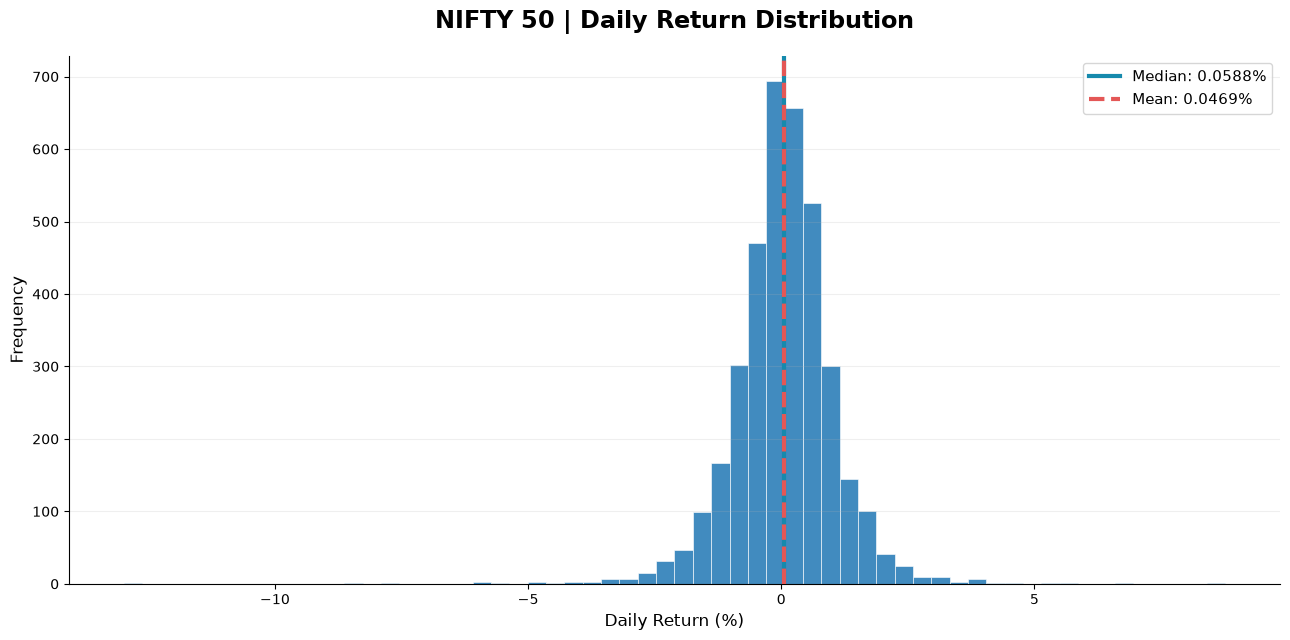

In [16]:
import matplotlib.pyplot as plt

returns = df["daily_return_pct"].dropna()

mean_return = returns.mean()
median_return = returns.median()

fig, ax = plt.subplots(figsize=(13, 6.5))

ax.hist(
    returns,
    bins=60,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.85
)

# Draw median first
ax.axvline(
    median_return,
    color="#168AAD",
    linewidth=3,
    linestyle="-",
    zorder=5,
    label=f"Median: {median_return:.4f}%"
)

# Draw mean second
ax.axvline(
    mean_return,
    color="#E45756",
    linewidth=3,
    linestyle="--",
    zorder=6,
    label=f"Mean: {mean_return:.4f}%"
)

ax.set_title(
    "NIFTY 50 | Daily Return Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Daily Return (%)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

ax.grid(axis="y", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper right", frameon=True, fontsize=11)

fig.tight_layout()
plt.show()

In [17]:
extreme_returns = df[
    ["Date", "Close", "daily_return_pct"]
].dropna(subset=["daily_return_pct"])

worst_days = extreme_returns.nsmallest(
    10, "daily_return_pct"
)

best_days = extreme_returns.nlargest(
    10, "daily_return_pct"
)

print("10 Worst Trading Days")
display(worst_days)

print("10 Best Trading Days")
display(best_days)

10 Worst Trading Days


,Date,Close,daily_return_pct
2064,2020-03-23,7610.250000,-12.980466
2057,2020-03-12,9590.150391,-8.301939
2059,2020-03-16,9197.400391,-7.612100
3101,2024-06-04,21884.500000,-5.929360
944,2015-08-24,7809.000000,-5.915098
2089,2020-05-04,9293.500000,-5.744484
2061,2020-03-18,8468.799805,-5.556454
2055,2020-03-09,10451.450195,-4.895604
2543,2022-02-24,16247.950195,-4.778104
2069,2020-03-30,8281.099609,-4.378054


10 Best Trading Days


,Date,Close,daily_return_pct
2073,2020-04-07,8792.200195,8.763210
2066,2020-03-25,8317.849609,6.624747
2063,2020-03-20,8745.450195,5.832915
1941,2019-09-20,11274.200195,5.319113
2278,2021-02-01,14281.200195,4.742351
2075,2020-04-09,9111.900391,4.150883
2067,2020-03-26,8641.450195,3.890436
2070,2020-03-31,8597.750000,3.823772
3332,2025-05-12,24924.699219,3.818307
470,2013-09-10,5896.750000,3.808712


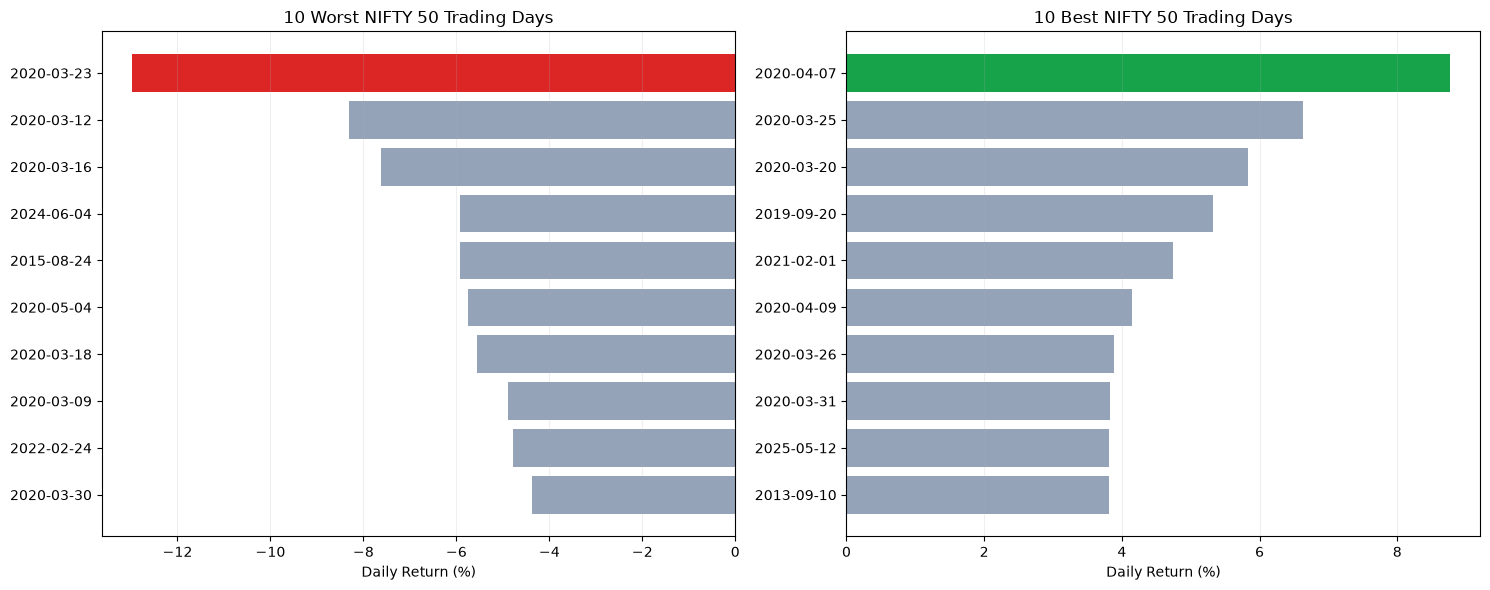

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Worst days
worst_colors = ["#DC2626"] + ["#94A3B8"] * 9

axes[0].barh(
    worst_days["Date"].dt.strftime("%Y-%m-%d"),
    worst_days["daily_return_pct"],
    color=worst_colors
)

axes[0].set_title("10 Worst NIFTY 50 Trading Days")
axes[0].set_xlabel("Daily Return (%)")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.2)


# Best days
best_colors = ["#16A34A"] + ["#94A3B8"] * 9

axes[1].barh(
    best_days["Date"].dt.strftime("%Y-%m-%d"),
    best_days["daily_return_pct"],
    color=best_colors
)

axes[1].set_title("10 Best NIFTY 50 Trading Days")
axes[1].set_xlabel("Daily Return (%)")
axes[1].invert_yaxis()
axes[1].grid(axis="x", alpha=0.2)

fig.tight_layout()
plt.show()

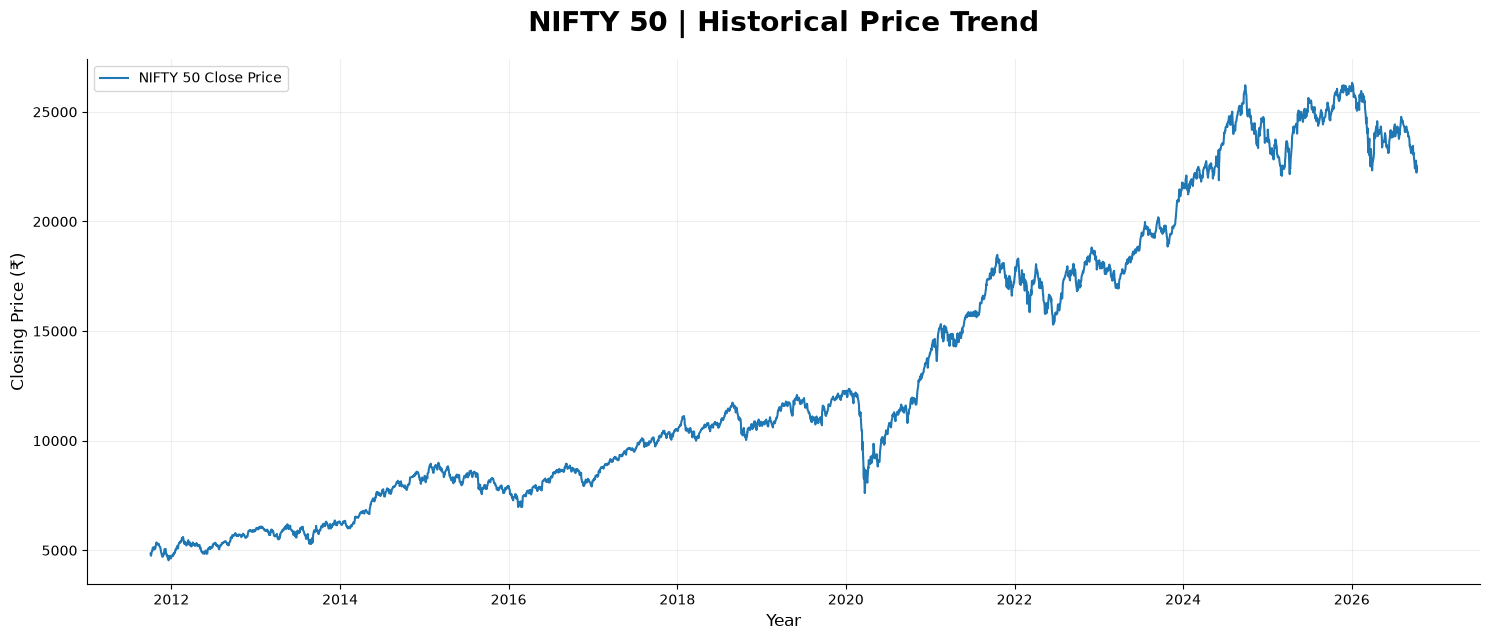

In [19]:
fig,ax = plt.subplots(figsize = (15,6.5))

ax.plot(df["Date"],df["Close"], linewidth=1.5,
        label="NIFTY 50 Close Price")

ax.set_title(
    "NIFTY 50 | Historical Price Trend",
    fontsize = 20,
    fontweight = "bold",
    pad = 20
    
)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Closing Price (₹)", fontsize=12)

ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

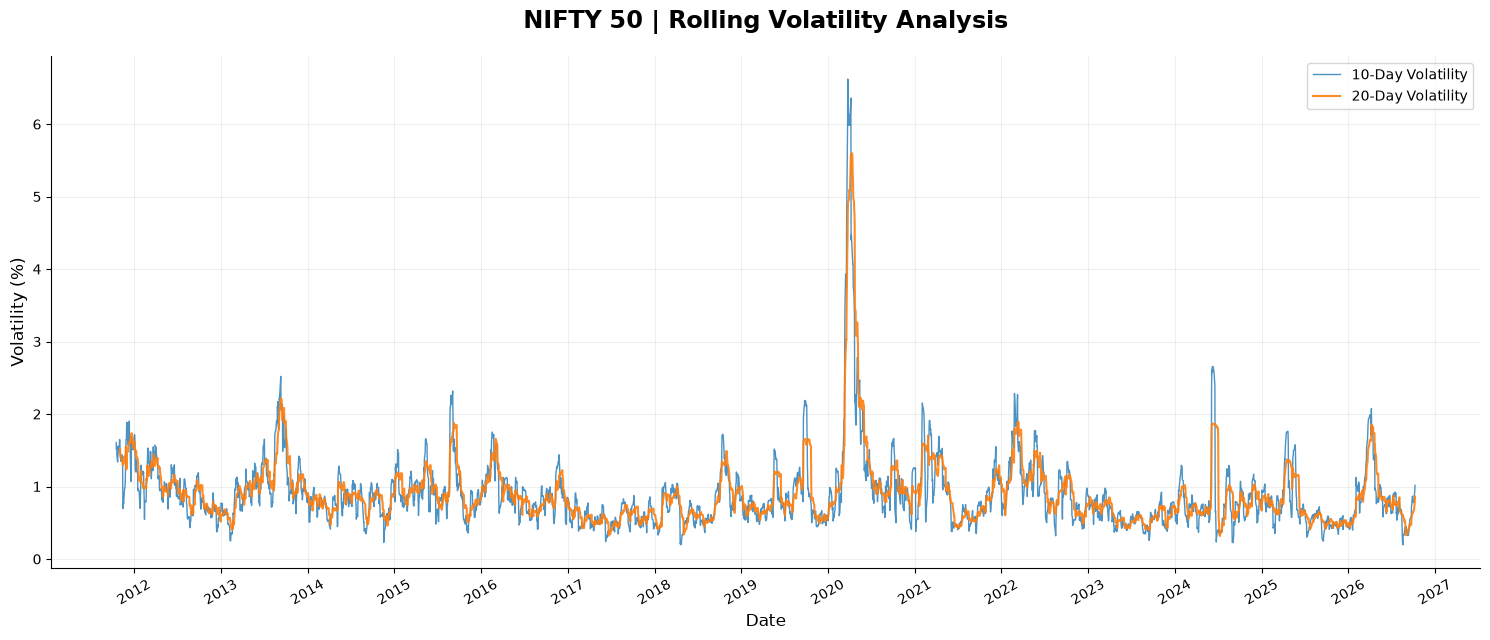

In [20]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(15, 6.5))

# 10-day volatility
ax.plot(
    df["Date"],
    df["volatility_10d"],
    linewidth=1,
    label="10-Day Volatility",
    alpha=0.8
)

# 20-day volatility
ax.plot(
    df["Date"],
    df["volatility_20d"],
    linewidth=1.5,
    label="20-Day Volatility",
    alpha=0.9
)

# Chart title
ax.set_title(
    "NIFTY 50 | Rolling Volatility Analysis",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Volatility (%)", fontsize=12)

# Date formatting
ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# Styling
ax.grid(alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper right")

plt.xticks(rotation=30)

fig.tight_layout()
plt.show()

In [21]:
high_volatility = df[
    ["Date", "Close", "volatility_10d", "volatility_20d"]
].dropna(subset="volatility_20d")
top_volatility = high_volatility.nlargest(10,"volatility_20d")

display(top_volatility)

,Date,Close,volatility_10d,volatility_20d
2076,2020-04-13,8993.849609,4.186445,5.596263
2075,2020-04-09,9111.900391,4.472399,5.595635
2073,2020-04-07,8792.200195,6.360440,5.571284
2074,2020-04-08,8748.750000,4.400049,5.562758
2077,2020-04-15,8925.299805,4.069355,5.295988
2078,2020-04-16,8992.799805,4.070288,5.217187
2070,2020-03-31,8597.750000,6.126596,5.088638
2071,2020-04-01,8253.799805,5.995039,5.085155
2072,2020-04-03,8083.799805,5.980324,5.081647
2079,2020-04-17,9266.750000,3.756740,4.977915


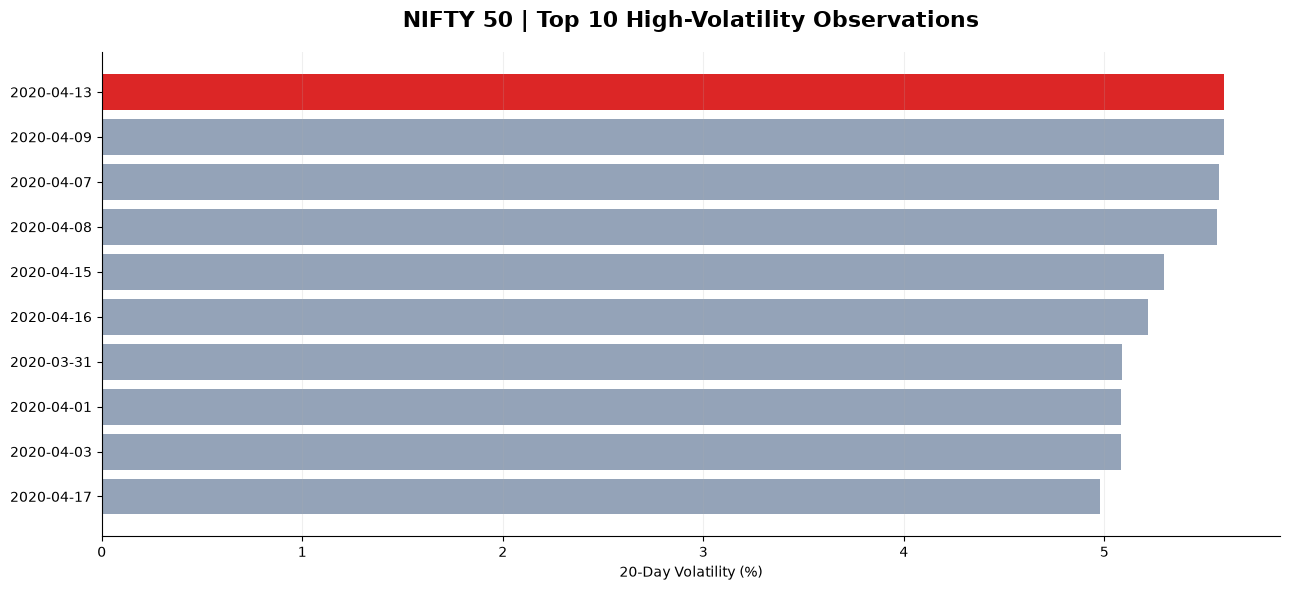

In [22]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.barh(
    top_volatility["Date"].dt.strftime("%Y-%m-%d"),
    top_volatility["volatility_20d"],
    color=["#DC2626"] + ["#94A3B8"] * 9
)

ax.set_title(
    "NIFTY 50 | Top 10 High-Volatility Observations",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("20-Day Volatility (%)")

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

In [23]:
volatility = df["volatility_20d"].dropna()

display(
    volatility.describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

count    3664.000000
mean        0.903536
std         0.470422
min         0.316922
10%         0.523197
25%         0.629403
50%         0.811071
75%         1.030610
90%         1.344623
95%         1.608479
99%         2.278251
max         5.596263
Name: volatility_20d, dtype: float64

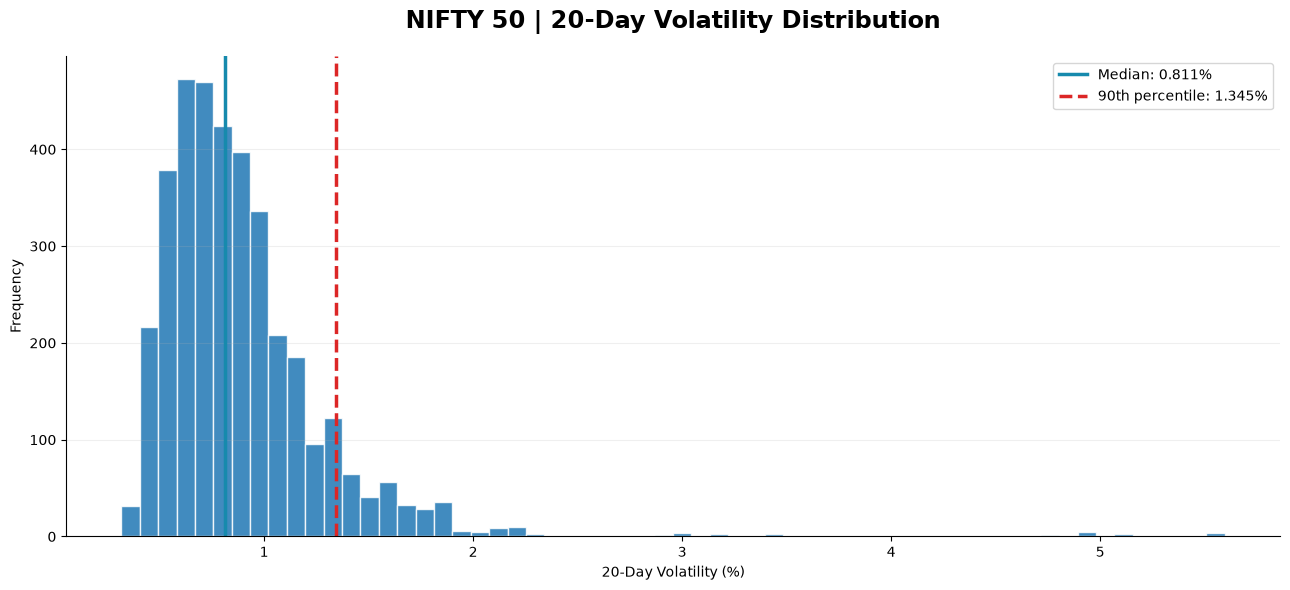

In [24]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.hist(
    volatility,
    bins=60,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    volatility.median(),
    color="#168AAD",
    linestyle="-",
    linewidth=2.5,
    label=f"Median: {volatility.median():.3f}%"
)

ax.axvline(
    volatility.quantile(0.90),
    color="#DC2626",
    linestyle="--",
    linewidth=2.5,
    label=f"90th percentile: {volatility.quantile(0.90):.3f}%"
)

ax.set_title(
    "NIFTY 50 | 20-Day Volatility Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("20-Day Volatility (%)")
ax.set_ylabel("Frequency")

ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()
fig.tight_layout()
plt.show()

In [26]:
correlation_data = df.select_dtypes(
    include="number"
).drop(
    columns=["next_close", "target_up"],
    errors="ignore"
)

correlation = correlation_data.corr(method = "pearson")


display(correlation.round(2))

,Adj Close,Close,High,Low,Open,Volume,daily_return_pct,return_5d_pct,return_10d_pct,sma_10,sma_20,volatility_10d,volatility_20d,rsi_14,price_vs_sma10_pct,price_vs_sma20_pct
Adj Close,1.00,1.00,1.00,1.00,1.00,0.32,-0.00,-0.01,-0.01,1.00,1.00,-0.19,-0.20,-0.00,-0.00,0.00
Close,1.00,1.00,1.00,1.00,1.00,0.32,-0.00,-0.01,-0.01,1.00,1.00,-0.19,-0.20,-0.00,-0.00,0.00
High,1.00,1.00,1.00,1.00,1.00,0.33,-0.01,-0.01,-0.01,1.00,1.00,-0.18,-0.19,-0.01,-0.01,-0.00
Low,1.00,1.00,1.00,1.00,1.00,0.32,-0.01,-0.01,-0.01,1.00,1.00,-0.19,-0.20,-0.00,-0.00,0.00
Open,1.00,1.00,1.00,1.00,1.00,0.33,-0.01,-0.01,-0.01,1.00,1.00,-0.19,-0.20,-0.01,-0.01,-0.00
Volume,0.32,0.32,0.33,0.32,0.33,1.00,-0.03,-0.04,-0.04,0.32,0.32,0.27,0.28,-0.01,-0.05,-0.05
daily_return_pct,-0.00,-0.00,-0.01,-0.01,-0.01,-0.03,1.00,0.44,0.31,-0.02,-0.02,0.02,0.03,0.23,0.53,0.37
return_5d_pct,-0.01,-0.01,-0.01,-0.01,-0.01,-0.04,0.44,1.00,0.71,-0.03,-0.04,-0.04,0.01,0.53,0.93,0.76
return_10d_pct,-0.01,-0.01,-0.01,-0.01,-0.01,-0.04,0.31,0.71,1.00,-0.03,-0.04,-0.20,-0.06,0.75,0.84,0.92
sma_10,1.00,1.00,1.00,1.00,1.00,0.32,-0.02,-0.03,-0.03,1.00,1.00,-0.18,-0.20,-0.02,-0.03,-0.03



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


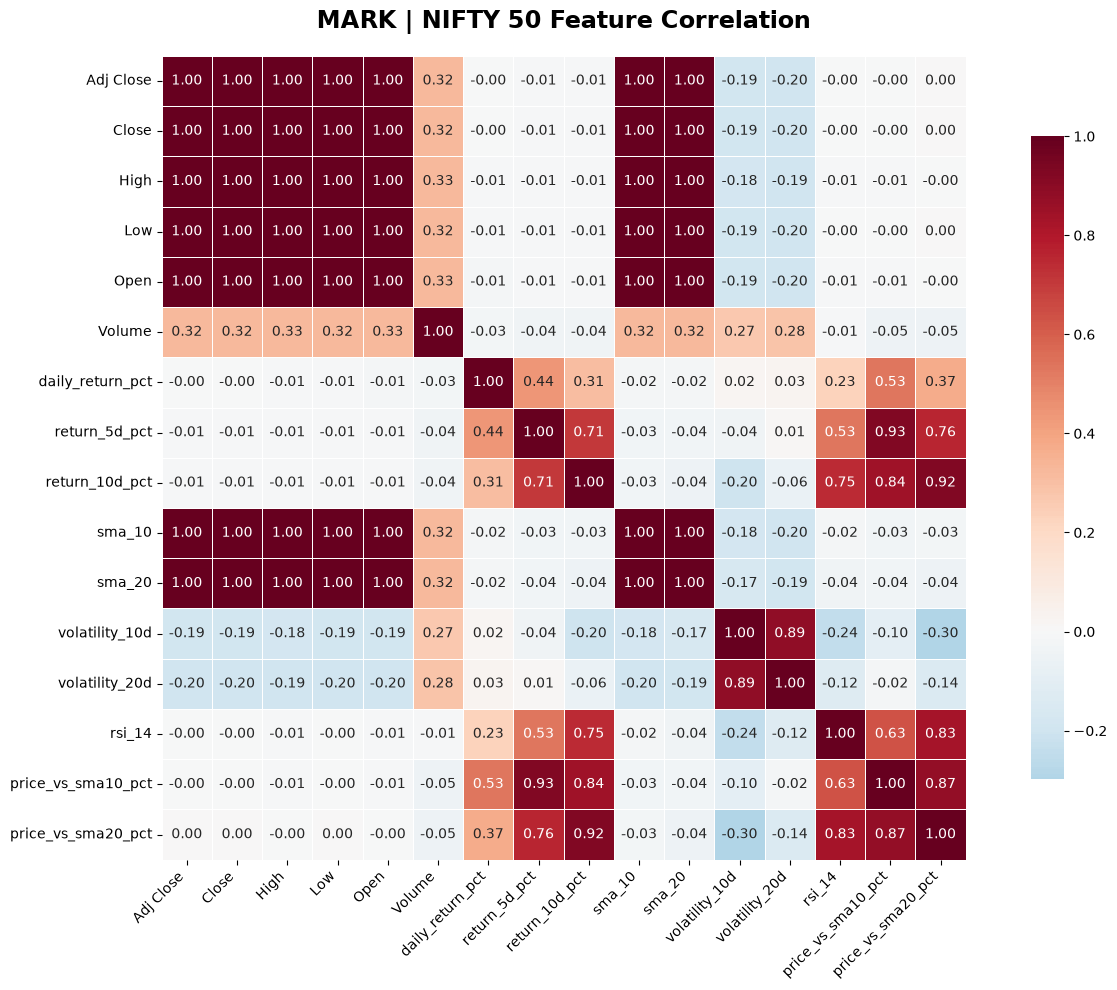

In [30]:
%pip install seaborn
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title(
    "MARK | NIFTY 50 Feature Correlation",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()
plt.show()

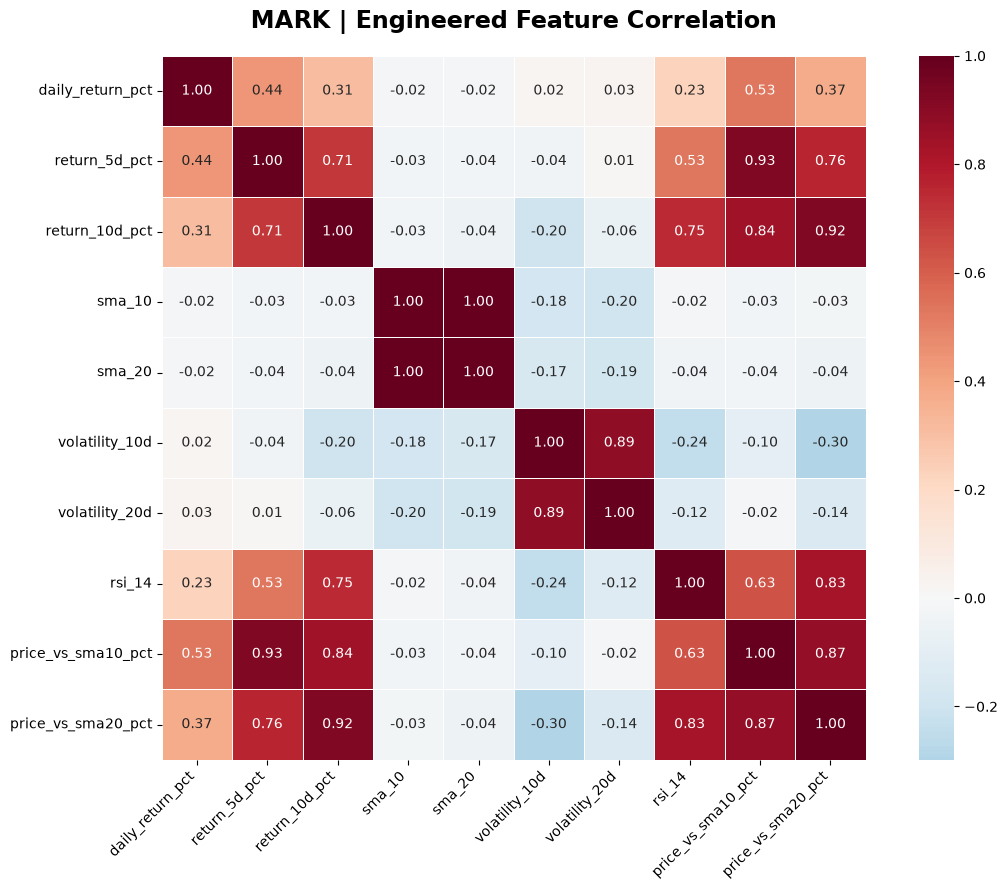

In [32]:
feature_columns = [
    "daily_return_pct",
    "return_5d_pct",
    "return_10d_pct",
    "sma_10",
    "sma_20",
    "volatility_10d",
    "volatility_20d",
    "rsi_14",
    "price_vs_sma10_pct",
    "price_vs_sma20_pct"
]
feature_correlation = df[
    feature_columns
].corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    feature_correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True,
    ax=ax
)

ax.set_title(
    "MARK | Engineered Feature Correlation",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()
plt.show()